cosas faltantes:

-comparacion con todos los modelos creados

-zona de aceptacion para una prediccion fallida

# Contexto del Dataset
---

    Deportation Data Project. (2026). Government data provided by ICE in response to a FOIA request to the Deportation Data Project and analyzed by Universidad Industrial De Santander [Dataset: Arrests]. 
GitHub: https://github.com/deportationdata/ice. Recuperado de https://deportationdata.org/data/processed/ice.html


**Origen y Fuente**

    Los datos utilizados en este proyecto provienen del **Deportation Data Project** (https://deportationdata.org/), una iniciativa pública de investigación que recopila y sistematiza registros administrativos de operaciones migratorias de la administración estadounidense.

    Los datos originales fueron recolectados por la **U.S. Immigration and Customs Enforcement (ICE)**, agencia federal responsable de la ejecución de leyes migratorias en Estados Unidos. ICE mantiene registros detallados de todas las aprehensiones, procesamientos de casos, y remociones que realiza.


**El Dataset**

    Dataset: ARRESTS (Registros de Aprehensiones)

    Período: Octubre 2022 - Agosto 2026 (~46 meses)

    Tamaño: 896,393 registros de aprehensión migratoria

    Variables: 33 columnas que incluyen información sobre fechas de aprehensión y cierre, características del detenido, clasificación legal del caso, programa asociado, y variables administrativas de control de calidad pero para el proyecto solo se tomaran 18 columnas relevantes.

**Contexto del Tema**

    El dataset contiene registros de personas aprehendidas por la agencia ICE en procesos relacionados con inmigración. Estos casos son procesados a través de diferentes programas operacionales, como el **ERO Criminal Alien Program** (enfoque de este proyecto), que gestiona casos de personas detenidas con antecedentes criminales o que representen una amenaza, así como otros programas como Alternatives to Detention y Non-Detained Docket Control.


**Acceso a los Datos**

    Los datos son públicos y gratuitos. Pueden descargarse desde:
https://deportationdata.org/data/processed/ice.html

    Documentación técnica y codebook disponibles en:
https://deportationdata.org/docs/ice/codebook.html

# Motivacion
---

## Principal

**Motivación**

    1). Predecir el programa por el que sera procesado una persona detenida por el ICE (final_program)
    2). Estimar cuntos dias pueden transcurrir desde el arresto hasta la salida del pais (days_until_departure)


**Problema**

    La información histórica de los arrestos realizados por el ICE permite analizar los casos registrados, pero no ofrece directamente una estimación anticipada de su duración ni del programa por el que serán procesados. Esto plantea la necesidad de identificar patrones en los datos que permitan estimar ambos resultados.


**Objetivo**

    Aplicar un modelo de machine learning para obtener las predicciones de nuestros targets

## Contenido por columna

**Información del arresto**

    apprehension_aor	        Área de responsabilidad de ICE donde ocurrió el arresto (Area of Responsibility).
    apprehension_criminality	Clasificación del tipo o nivel de criminalidad atribuido a la persona.
    apprehension_date	        Fecha en la que ocurrió el arresto.

    event_landmark	                Lugar o referencia específica donde ocurrió el evento.

    apprehension_method	        Método o modalidad mediante la cual ICE realizó el arresto.

    apprehension_state_filled_in	Estado de EE. UU. asignado o completado para el registro.
    apprehension_state_fill_source	Indica de dónde se obtuvo el estado completado.

    apprehension_state_original	Estado registrado originalmente en la fuente de datos.

    apprehension_city_original	Ciudad registrada originalmente para el arresto.
    apprehension_city_common_case	Nombre de ciudad normalizado para facilitar la comparación entre registros.

    apprehension_date_time	        Fecha y hora exactas del arresto, cuando están disponibles.
    apprehension_method_simple	Versión simplificada del método de arresto, agrupando modalidades similares.

**Información personal**

    birth_year	                Año de nacimiento de la persona.

    gender	                        Género registrado de la persona.

    citizenship_country         	País de ciudadanía de la persona.

    age_at_apprehension_approximate	
                                    Edad aproximada que tenía la persona cuando fue arrestada.
                                    Por ejemplo, si una persona nació en 1985 y fue arrestada en 2025, su edad aproximada sería de 40 años.

**Información del proceso migratorio**

    case_category	                Categoría o clasificación del caso migratorio.
    case_status	                Estado o situación del proceso migratorio.
    case_threat_level               Nivel de amenaza o clasificación de riesgo asignada al caso.

    final_order_date	        Fecha en que se emitió la orden final del proceso.
    final_order_yes_no	        Indica si existe una orden final: YES o NO.
    
    final_program         	        Programa de ICE asociado al procesamiento final del caso.
    final_program_group             Grupo al que pertenece el programa final.
    final_order_before_apprehension	
                                    Indica si la orden final ya existía antes del arresto.

# Librerias
---

In [90]:
%pip install -q category_encoders requests polars seaborn pyarrow
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [215]:
from io import BytesIO
import requests
import polars as pl


import pandas as pd
import numpy as  np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.preprocessing import OneHotEncoder
from category_encoders import CountEncoder

# Clasificacion
from sklearn.model_selection import train_test_split

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix)

#Regresion
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.svm import LinearSVR
from sklearn.dummy import DummyRegressor

In [92]:
df = pl.read_parquet("arrests-latest.parquet")

df = df.to_pandas(use_pyarrow_extension_array=True)

# Manejo inicial
---

## Vista

In [93]:
display(df.shape, df.head(3))

(896393, 34)

,apprehension_aor,apprehension_criminality,apprehension_date,event_landmark,apprehension_method,apprehension_state_filled_in,apprehension_state_fill_source,apprehension_state_original,apprehension_city_original,birth_year,...,apprehension_method_simple,final_order_before_apprehension,duplicate_episode_identifier,duplicate_episode_first,duplicate_likely,duplicate_drop_row,apprehension_city_common_case,file_original,sheet_original,row_original
0,Miami Area of Responsibility,3 Other Immigration Violator,2025-11-09,JACKSONVILLE FL ERO,Non-Custodial Arrest,FLORIDA,original,FLORIDA,JACKSONVILLE,1985,...,At-Large Arrest,False,1,True,False,False,Jacksonville,Hausman_ARS_FY2026_LESA-STU_FINAL Highlighted....,Details,12737
1,Dallas Area of Responsibility,1 Convicted Criminal,2023-07-21,ARLINGTON POLICE DEPARTMENT,CAP Local Incarceration,TEXAS,original,TEXAS,Dallas,1994,...,Custodial Arrest,True,1,True,False,False,Dallas,Hausman_ARS_FY2023_LESA-STU_FINAL Highlighted....,Details,2274
2,Dallas Area of Responsibility,1 Convicted Criminal,2025-02-19,<NA>,CAP Local Incarceration,<NA>,<NA>,<NA>,<NA>,1994,...,Custodial Arrest,True,2,True,False,False,<NA>,Hausman_ARS_FY2025_LESA-STU_FINAL Highlighted....,Details,3279


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 896393 entries, 0 to 896392
Data columns (total 34 columns):
 #   Column                           Non-Null Count   Dtype                         
---  ------                           --------------   -----                         
 0   apprehension_aor                 886541 non-null  large_string[pyarrow]         
 1   apprehension_criminality         896393 non-null  large_string[pyarrow]         
 2   apprehension_date                896393 non-null  date32[day][pyarrow]          
 3   event_landmark                   695320 non-null  large_string[pyarrow]         
 4   apprehension_method              896393 non-null  large_string[pyarrow]         
 5   apprehension_state_filled_in     852962 non-null  large_string[pyarrow]         
 6   apprehension_state_fill_source   852962 non-null  large_string[pyarrow]         
 7   apprehension_state_original      787490 non-null  large_string[pyarrow]         
 8   apprehension_city_origin

In [95]:
print(df.dtypes)

apprehension_aor                            large_string[pyarrow]
apprehension_criminality                    large_string[pyarrow]
apprehension_date                            date32[day][pyarrow]
event_landmark                              large_string[pyarrow]
apprehension_method                         large_string[pyarrow]
apprehension_state_filled_in                large_string[pyarrow]
apprehension_state_fill_source              large_string[pyarrow]
apprehension_state_original                 large_string[pyarrow]
apprehension_city_original                  large_string[pyarrow]
birth_year                                         int32[pyarrow]
case_category                               large_string[pyarrow]
case_status                                 large_string[pyarrow]
case_threat_level                           large_string[pyarrow]
citizenship_country                         large_string[pyarrow]
departed_date                                date32[day][pyarrow]
departure_

## Seleccion de columnas

In [96]:
print("columnas iniciales:", len(df.columns))
columnas = [
    'apprehension_aor',
    'apprehension_date',
    'departed_date',
    'apprehension_state_filled_in',
    'apprehension_city_original',
    'apprehension_criminality',
    'apprehension_method_simple',
    'citizenship_country',
    'gender',
    'birth_year',
    'final_program',
    'age_at_apprehension_approximate',
    'final_order_before_apprehension',
    'case_category',
    'case_threat_level',
] 
df = df[columnas]
print("columnas actuales:", len(df.columns))

columnas iniciales: 34
columnas actuales: 15


In [97]:
# valores unicos por columna
df.nunique(dropna=False).sort_values(ascending=False)

apprehension_city_original         18513
departed_date                       1508
apprehension_date                   1406
citizenship_country                  207
birth_year                           101
age_at_apprehension_approximate      100
apprehension_state_filled_in          64
case_category                         35
apprehension_aor                      27
final_program                         14
case_threat_level                      5
apprehension_method_simple             4
apprehension_criminality               3
gender                                 3
final_order_before_apprehension        2
dtype: int64

In [98]:
df.head(3)

,apprehension_aor,apprehension_date,departed_date,apprehension_state_filled_in,apprehension_city_original,apprehension_criminality,apprehension_method_simple,citizenship_country,gender,birth_year,final_program,age_at_apprehension_approximate,final_order_before_apprehension,case_category,case_threat_level
0,Miami Area of Responsibility,2025-11-09,2026-01-24,FLORIDA,JACKSONVILLE,3 Other Immigration Violator,At-Large Arrest,GUATEMALA,Male,1985,ERO Criminal Alien Program,40.0,False,[1A] Voluntary Departure - Un-Expired and Un-E...,NA
1,Dallas Area of Responsibility,2023-07-21,2025-02-20,TEXAS,Dallas,1 Convicted Criminal,Custodial Arrest,MEXICO,Male,1994,ERO Criminal Alien Program,29.0,True,[16] Reinstated Final Order,3
2,Dallas Area of Responsibility,2025-02-19,2025-02-20,<NA>,<NA>,1 Convicted Criminal,Custodial Arrest,MEXICO,Male,1994,Alternatives to Detention,31.0,True,[16] Reinstated Final Order,3


## Nulos

In [99]:
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

departed_date                      35.05
apprehension_city_original         12.37
apprehension_state_filled_in        4.85
case_threat_level                   2.80
case_category                       2.80
apprehension_aor                    1.10
apprehension_date                   0.00
apprehension_method_simple          0.00
apprehension_criminality            0.00
citizenship_country                 0.00
gender                              0.00
final_program                       0.00
birth_year                          0.00
final_order_before_apprehension     0.00
age_at_apprehension_approximate     0.00
dtype: float64


In [100]:
print("Numero de filas iniciales: ", df.shape[0])
df= df.dropna()
print("Numero de filas finales: ", df.shape[0])

Numero de filas iniciales:  896393
Numero de filas finales:  523866


## Valores categoricos a numericos

In [101]:
# Preprocesamiento para que el modelo de ML entienda las columnas
columnas_onehot = [
    "apprehension_aor",
    "apprehension_state_filled_in",
    "apprehension_criminality",
    "apprehension_method_simple",
    "gender",
    'case_threat_level'
]
columnas_frequency = [
    "apprehension_city_original",
    "citizenship_country"
]

# One-Hot Encoding
onehot = OneHotEncoder(sparse_output=False )

encoded_onehot = onehot.fit_transform(df[columnas_onehot])

df_onehot = pd.DataFrame(
    data=encoded_onehot,
    columns=onehot.get_feature_names_out(columnas_onehot),
    index=df.index
)

# Frequency Encoding
frequency = CountEncoder(
    cols=columnas_frequency,
    normalize=True
)
df_frequency = frequency.fit_transform(
    df[columnas_frequency]
)

# Reemplazar las columnas originales
df = df.drop(
    columns=columnas_onehot + columnas_frequency
)
df = pd.concat(
    [df, df_onehot, df_frequency],
    axis=1
)

# Modelos ML
---

## Classifier (final_program)

### Manejo Inicial

In [102]:
df_clasificator = df.drop(columns=[
    'departed_date',
    'apprehension_date',
    'case_category',
    'final_order_before_apprehension',
    'days_until_departure'
], errors='ignore').copy()

print(df_clasificator.shape, "\n")
print(df_clasificator.info())

(523866, 108) 

<class 'pandas.core.frame.DataFrame'>
Index: 523866 entries, 0 to 896390
Columns: 108 entries, birth_year to citizenship_country
dtypes: double[pyarrow](1), float64(105), int32[pyarrow](1), large_string[pyarrow](1)
memory usage: 445.9 MB
None


In [103]:
# proporcion de categorias del target 1
df_clasificator.final_program.value_counts(normalize=True)

final_program
ERO Criminal Alien Program             0.657052
Fugitive Operations                    0.175459
Non-Detained Docket Control            0.057499
Alternatives to Detention              0.039266
Detained Docket Control                 0.02493
Detention and Deportation              0.018127
287G Program                           0.016859
Mobile Criminal Alien Team             0.006609
287g Task Force                         0.00217
Juvenile                               0.000718
ERO Criminal Prosecutions              0.000683
Law Enforcement Area Response Units    0.000473
Joint Criminal Alien Response Team     0.000149
Violent Criminal Alien Section         0.000006
Name: proportion, dtype: double[pyarrow]

In [104]:
df_clasificator = df_clasificator[df_clasificator["final_program"].isin((
    "ERO Criminal Alien Program",
    "Fugitive Operations",
    "Non-Detained Docket Control"
))]

In [ ]:
X_classifier=df_clasificator.drop(columns=['final_program'])
y_classifier=df_clasificator['final_program']

Xclas_train, Xclas_aux, yclas_train, yclas_aux = train_test_split(X_classifier, y_classifier, test_size=0.3, stratify=y_classifier, random_state=67)

Xclas_test, Xclas_val, yclas_test, yclas_val = train_test_split(Xclas_aux, yclas_aux, test_size=0.5, stratify=yclas_aux, random_state=67)

### Gaussian Naive Bayes

In [194]:
gnb = GaussianNB()

gnb.fit(Xclas_train, yclas_train)

ypred_test_gnb = gnb.predict(Xclas_test)
ypred_val_gnb = gnb.predict(Xclas_val)

####    Resultados GNB

In [195]:
print("Accuracy:", accuracy_score(yclas_test, ypred_test_gnb))
print("Accuracy:", accuracy_score(yclas_val, ypred_val_gnb))

print("\nClassification Report test:")
print(classification_report(yclas_test, ypred_test_gnb))
print("\nClassification Report validation:")
print(classification_report(yclas_val, ypred_val_gnb))

Accuracy: 0.4878920652429247
Accuracy: 0.485975740533327

Classification Report test:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.88      0.55      0.68     72283
        Fugitive Operations       0.39      0.13      0.20     19302
Non-Detained Docket Control       0.11      0.83      0.20      6326

                   accuracy                           0.49     97911
                  macro avg       0.46      0.50      0.36     97911
               weighted avg       0.74      0.49      0.55     97911


Classification Report validation:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.88      0.55      0.68     30979
        Fugitive Operations       0.38      0.13      0.20      8273
Non-Detained Docket Control       0.11      0.83      0.20      2711

                   accuracy                           0.49     41963
                  macro avg       0.46      0.

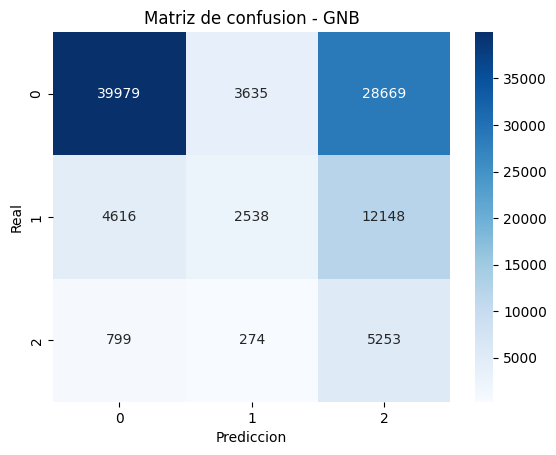

In [197]:
sns.heatmap(
    confusion_matrix(yclas_test, ypred_test_gnb),
    annot=True,
    fmt="d",
    cmap="Blues",
)
plt.xlabel("Prediccion")
plt.ylabel("Real")
plt.title("Matriz de confusion - GNB")
plt.show()

0. ERO Criminal Alien Program 
1. Fugitive Operations
2. Non-Detained Docket Control

### Desicion Tree Classifier

**Hiperparametro**

    max_depth	        Profundidad máxima del árbol.
    min_samples_split	Mínimo de registros necesarios para dividir un nodo.
    min_samples_leaf	Mínimo de registros que debe tener cada hoja.

In [109]:
# Hiperparametros que se van a probar
param_grid = {
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

# Validacion cruzada estratificada
kf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

# Busqueda aleatoria de hiperparametros
grid_dt = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=67),
    param_distributions=param_grid,
    n_iter=10,
    cv=kf,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=67,
    verbose=1
)

# Entrenamiento y busqueda
grid_dt.fit(Xclas_train, yclas_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=67)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",67
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns t

In [116]:
print("Mejores hiperparametros:")
print(grid_dt.best_params_)

print("\nMejor F1 Macro en validacion cruzada:")
print(grid_dt.best_score_)

Mejores hiperparametros:
{'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': None}

Mejor F1 Macro en validacion cruzada:
0.6575069187510393


####    Resultados DTC

In [207]:
mejor_dt = grid_dt.best_estimator_

ypred_dt_test = mejor_dt.predict(Xclas_test)
ypred_dt_val = mejor_dt.predict(Xclas_val)

print("Accuracy test:", accuracy_score(yclas_test, ypred_dt_test))

print("\nClassification Report test:")
print(classification_report(yclas_test, ypred_dt_test))

print("Accuracy validation:", accuracy_score(yclas_val, ypred_dt_val))

print("\nClassification Report validation:")
print(classification_report(yclas_val, ypred_dt_val))

print("\nProfundidad del arbol:", mejor_dt.get_depth())
print("Cantidad de hojas:", mejor_dt.get_n_leaves())

Accuracy test: 0.8196831816649814

Classification Report test:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.87      0.92      0.90     72283
        Fugitive Operations       0.64      0.56      0.60     19302
Non-Detained Docket Control       0.63      0.41      0.50      6326

                   accuracy                           0.82     97911
                  macro avg       0.71      0.63      0.66     97911
               weighted avg       0.81      0.82      0.81     97911

Accuracy validation: 0.8171961013273599

Classification Report validation:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.87      0.92      0.89     30979
        Fugitive Operations       0.63      0.57      0.60      8273
Non-Detained Docket Control       0.62      0.40      0.49      2711

                   accuracy                           0.82     41963
                  macro avg  

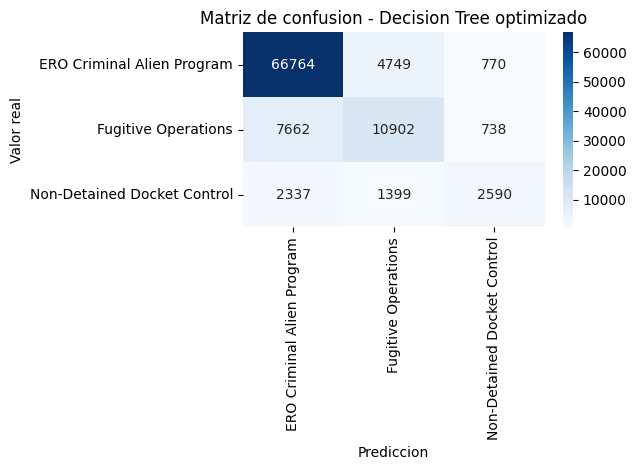

In [201]:
sns.heatmap(
    confusion_matrix(yclas_test, ypred_dt_test),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=mejor_dt.classes_,
    yticklabels=mejor_dt.classes_
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - Decision Tree optimizado")
plt.tight_layout()
plt.show()

### Random Forest Classifier

In [124]:
# Hiperparametros que se van a probar
param_grid_rf = {
    'n_estimators': [100, 150, 200],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 'log2']
}

# Validacion cruzada estratificada
kf_rf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

# Busqueda aleatoria de hiperparametros
grid_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=67,
        n_jobs=1
    ),
    param_distributions=param_grid_rf,
    n_iter=10,
    cv=kf_rf,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=67,
    verbose=1
)

# Entrenamiento y busqueda
grid_rf.fit(Xclas_train, yclas_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=67)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",67
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit``

In [125]:
print("Mejores hiperparametros:")
print(grid_rf.best_params_)

print("\nMejor F1 Macro en validacion cruzada:")
print(grid_rf.best_score_)

Mejores hiperparametros:
{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

Mejor F1 Macro en validacion cruzada:
0.6508132867129253


####    Resultados RFC

In [205]:
mejor_rf = grid_rf.best_estimator_
ypred_rf = mejor_rf.predict(Xclas_val)
ypred_rf_test = mejor_rf.predict(Xclas_test)

print("Accuracy test:", accuracy_score(yclas_test, ypred_rf_test))

print("\nClassification Report test:")
print(classification_report(yclas_test, ypred_rf_test))

print("Accuracy validation:", accuracy_score(yclas_val, ypred_rf))

print("\nClassification Report validation:")
print(classification_report(yclas_val, ypred_rf))

print("\nCantidad de arboles:", len(mejor_rf.estimators_))
print("Profundidad maxima:", max(
    arbol.get_depth() for arbol in mejor_rf.estimators_
))

Accuracy test: 0.8245447396104626

Classification Report test:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.87      0.94      0.90     72283
        Fugitive Operations       0.66      0.56      0.60     19302
Non-Detained Docket Control       0.70      0.35      0.47      6326

                   accuracy                           0.82     97911
                  macro avg       0.74      0.62      0.66     97911
               weighted avg       0.81      0.82      0.81     97911

Accuracy validation: 0.8239163072230298

Classification Report validation:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.87      0.94      0.90     30979
        Fugitive Operations       0.65      0.56      0.60      8273
Non-Detained Docket Control       0.69      0.34      0.46      2711

                   accuracy                           0.82     41963
                  macro avg  

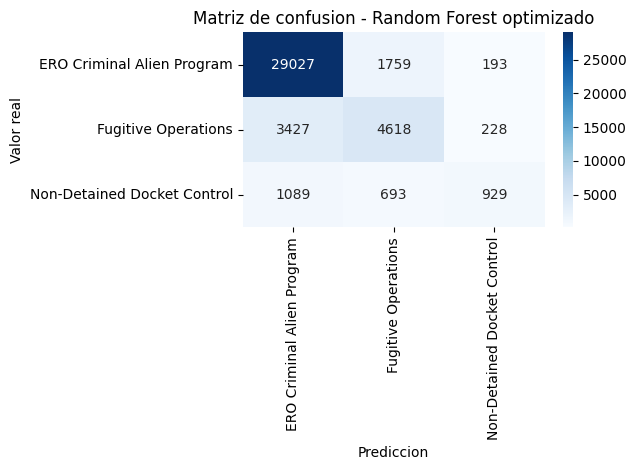

In [127]:
sns.heatmap(
    confusion_matrix(yclas_val, ypred_rf),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=mejor_rf.classes_,
    yticklabels=mejor_rf.classes_
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - Random Forest optimizado")
plt.tight_layout()
plt.show()

### Support Vector Classifier

In [131]:
# Pipeline de escalado y modelo
pipeline_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVC(
        random_state=67,
        max_iter=5000
    ))
])

# Hiperparametros que se van a probar
param_grid_svc = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

# Validacion cruzada estratificada
kf_svc = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

# Busqueda aleatoria
grid_svc = RandomizedSearchCV(
    estimator=pipeline_svc,
    param_distributions=param_grid_svc,
    n_iter=6,
    cv=kf_svc,
    scoring='f1_macro',
    n_jobs=2,
    random_state=67,
    verbose=1
)

# Entrenamiento y busqueda
grid_svc.fit(Xclas_train, yclas_train)

Fitting 3 folds for each of 6 candidates, totalling 18 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=67))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",6
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",67
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index

In [133]:
print("Mejores hiperparametros:")
print(grid_svc.best_params_)

print("\nMejor F1 Macro en validacion cruzada:")
print(grid_svc.best_score_)

Mejores hiperparametros:
{'model__class_weight': 'balanced', 'model__C': 10}

Mejor F1 Macro en validacion cruzada:
0.6085524776909775


####    Resultados SVC

In [206]:
mejor_svc = grid_svc.best_estimator_
ypred_svc_test = mejor_svc.predict(Xclas_test)
ypred_svc = mejor_svc.predict(Xclas_val)

print("Accuracy test:", accuracy_score(yclas_test, ypred_svc_test))

print("\nClassification Report test:")
print(classification_report(yclas_test, ypred_svc_test))

print("Accuracy validation:", accuracy_score(yclas_val, ypred_svc))

print("\nClassification Report validation:")
print(classification_report(yclas_val, ypred_svc))

print("\nConfusion Matrix:")
print(confusion_matrix(yclas_val, ypred_svc))

Accuracy test: 0.7707918415704058

Classification Report test:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.90      0.84      0.87     72283
        Fugitive Operations       0.52      0.61      0.56     19302
Non-Detained Docket Control       0.35      0.43      0.39      6326

                   accuracy                           0.77     97911
                  macro avg       0.59      0.63      0.61     97911
               weighted avg       0.79      0.77      0.78     97911

Accuracy validation: 0.7718227962729071

Classification Report validation:
                             precision    recall  f1-score   support

 ERO Criminal Alien Program       0.90      0.84      0.87     30979
        Fugitive Operations       0.52      0.62      0.57      8273
Non-Detained Docket Control       0.35      0.42      0.39      2711

                   accuracy                           0.77     41963
                  macro avg  

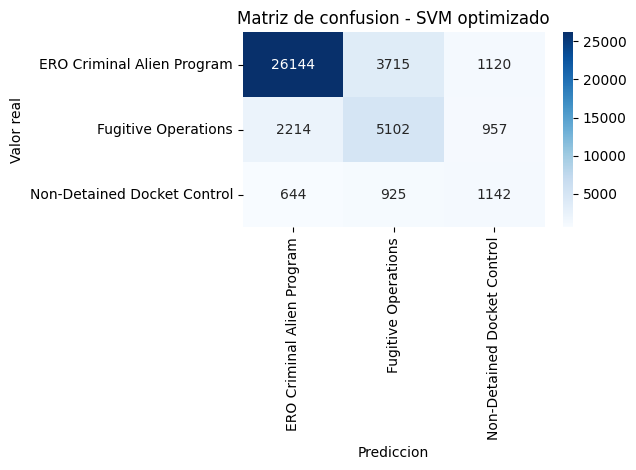

In [135]:
sns.heatmap(
    confusion_matrix(yclas_val, ypred_svc),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=mejor_svc.classes_,
    yticklabels=mejor_svc.classes_
)

plt.xlabel("Prediccion")
plt.ylabel("Valor real")
plt.title("Matriz de confusion - SVM optimizado")
plt.tight_layout()
plt.show()

### Comparacion Clasifier

In [136]:
# Gaussian Naive Bayes
ypred_gnb = gnb.predict(Xclas_val)

# Decision Tree
ypred_dt = mejor_dt.predict(Xclas_val)

# Random Forest
ypred_rf = mejor_rf.predict(Xclas_val)

# Support Vector Machine
ypred_svc = mejor_svc.predict(Xclas_val)

In [137]:
modelos = {
    'GaussianNB': ypred_gnb,
    'Decision Tree': ypred_dt,
    'Random Forest': ypred_rf,
    'SVM': ypred_svc
}

resultados = []

for nombre, predicciones in modelos.items():

    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(yclas_val, predicciones),
        'Precision Macro': precision_score(
            yclas_val, predicciones,
            average='macro',
            zero_division=0
        ),
        'Recall Macro': recall_score(
            yclas_val, predicciones,
            average='macro',
            zero_division=0
        ),
        'F1 Macro': f1_score(
            yclas_val, predicciones,
            average='macro',
            zero_division=0
        )
    })

df_comparacion = pd.DataFrame(resultados)

df_comparacion = df_comparacion.sort_values(
    by='F1 Macro',
    ascending=False
).reset_index(drop=True)

print(df_comparacion.round(4))

          Modelo  Accuracy  Precision Macro  Recall Macro  F1 Macro
0  Decision Tree    0.8172           0.7078        0.6288    0.6592
1  Random Forest    0.8239           0.7356        0.6126    0.6531
2            SVM    0.7718           0.5933        0.6273    0.6078
3     GaussianNB    0.4860           0.4580        0.5042    0.3576


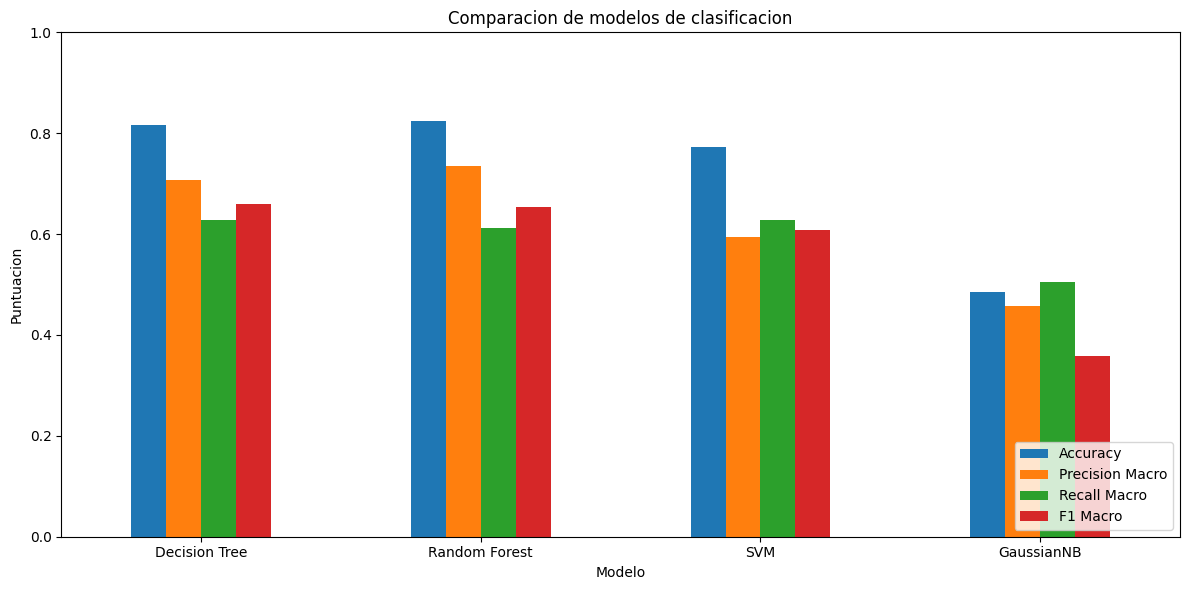

In [138]:
metricas = [
    'Accuracy',
    'Precision Macro',
    'Recall Macro',
    'F1 Macro'
]

df_grafica = df_comparacion.set_index('Modelo')[metricas]

df_grafica.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparacion de modelos de clasificacion')
plt.ylabel('Puntuacion')
plt.xlabel('Modelo')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Regresor (days_until_departure)

### Manejo Inicial

In [110]:
df_regresor = df.drop(columns=[
    'apprehension_date',
    'departed_date'
]).copy()
df_regresor.shape

(523866, 110)

In [111]:
# target = 'days_until_departure'

# Convertir las fechas a formato datetime
df['apprehension_date'] = pd.to_datetime(df['apprehension_date'], errors='coerce')
df['departed_date'] = pd.to_datetime(df['departed_date'], errors='coerce')

# Calcular los días entre las fechas
df_regresor['days_until_departure'] = (df['departed_date'] - df['apprehension_date']).dt.days

In [112]:
print("Cantidad de registros:", len(df))

print("\nCantidad de salidas negativas:")
print((df_regresor['days_until_departure'] < 0).sum())

print("\nCantidad de salidas nulas:")
print("Nulos:", df_regresor['days_until_departure'].isna().sum())

print("\nCantidad de salidas iguales a cero:")
print((df_regresor['days_until_departure'] == 0).sum())

print("\nCantidad de salidas positivas:")
print((df_regresor['days_until_departure'] > 0).sum())

print("\n", df_regresor['days_until_departure'].describe().round(1))

Cantidad de registros: 523866

Cantidad de salidas negativas:
1232

Cantidad de salidas nulas:
Nulos: 0

Cantidad de salidas iguales a cero:
40263

Cantidad de salidas positivas:
482371

 count    523866.0
mean         57.8
std         144.5
min      -36280.0
25%           7.0
50%          22.0
75%          57.0
max        1392.0
Name: days_until_departure, dtype: float64


    ¿Que significa que el valor minimo sea -36512.0?

    Es un registro que debemos investigar, porque no representa el tiempo transcurrido desde ese arresto hasta esa salida. Podría estar relacionado con registros historicos, episodios anteriores o inconsistencias en los datos

    Por eso decidimos excluir las duraciones negativas de nuestra variable objetivo, pero conservar las que son iguales a cero o positivas

In [113]:
# Quitamos inconsistencias (salida antes del arresto) y valores extremos (percentil 99)
df_regresor = df_regresor[df_regresor["days_until_departure"] >= 0]
df_regresor = df_regresor[df_regresor["days_until_departure"] <= df_regresor["days_until_departure"].quantile(0.98)]
df_regresor.shape

(512187, 111)

In [114]:
columnas_frequency = [
    "case_category",
    "final_program"
]
# Frequency Encoding
frequency = CountEncoder(cols=columnas_frequency,normalize=True)
df_frequency = frequency.fit_transform(df_regresor[columnas_frequency])

# Reemplazar columnas originales
df_regresor = df_regresor.drop(columns = columnas_frequency)
df_regresor = pd.concat([df_regresor, df_frequency], axis=1)

In [ ]:
X_regresor = df_regresor.drop(columns=['days_until_departure'])
y_regresor = df_regresor['days_until_departure']

Xreg_train, Xreg_aux, yreg_train, yreg_aux = train_test_split(X_regresor, y_regresor, test_size=0.3, random_state=67)

Xreg_test, Xreg_val, yreg_test, yreg_val = train_test_split(Xreg_aux, yreg_aux, test_size=0.5, random_state=67)

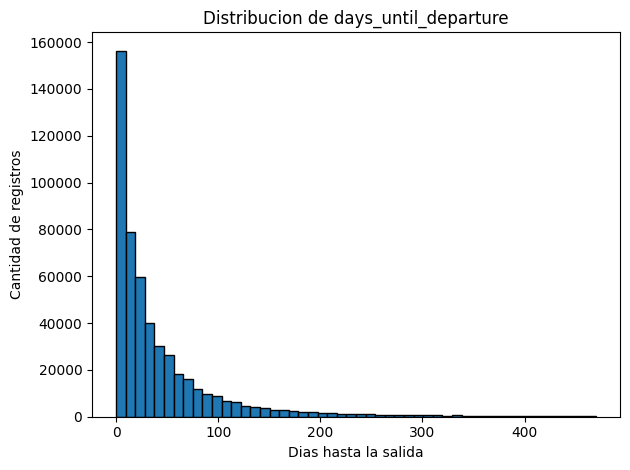

In [187]:
plt.hist(
    y_regresor,
    bins=50,
    edgecolor='black'
)

plt.xlabel("Dias hasta la salida")
plt.ylabel("Cantidad de registros")
plt.title("Distribucion de days_until_departure")
plt.tight_layout()
plt.show()

    Metrica	        Interpretacion	                            ¿Que buscamos?
    MAE	        Error absoluto promedio en días	            Menor
    MSE	        Error cuadrático promedio	            Menor
    RMSE	        Error típico penalizando errores grande     Menor
    R²	        Variabilidad explicada por el modelo	    Mayor

### Desicion Tree Regresor

In [ ]:
# Hiperparametros que se van a probar
param_grid_dt = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

# Validacion cruzada
kf_dt = KFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

# Busqueda aleatoria
grid_dt_reg = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=67),
    param_distributions=param_grid_dt,
    n_iter=10,
    cv=kf_dt,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    random_state=67,
    verbose=1
)

# Entrenamiento y busqueda
grid_dt_reg.fit(Xreg_train, yreg_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=67)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 5, ...], 'min_samples_split': [2, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",67
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function

In [144]:
print("Mejores hiperparametros:")
print(grid_dt_reg.best_params_)

print("\nMejor MAE en validacion cruzada:")
print(-grid_dt_reg.best_score_)

Mejores hiperparametros:
{'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': 15}

Mejor MAE en validacion cruzada:
29.490502203694263


####    Resultado

In [208]:
mejor_dt_reg = grid_dt_reg.best_estimator_
ypred_dt_reg_test = mejor_dt_reg.predict(Xreg_test)
ypred_dt_reg = mejor_dt_reg.predict(Xreg_val)

print("Profundidad del arbol:", mejor_dt_reg.get_depth())
print("Cantidad de hojas:", mejor_dt_reg.get_n_leaves())

print(" ")
print("test")
print("MAE:", mean_absolute_error(yreg_test, ypred_dt_reg_test))
print("MSE:", mean_squared_error(yreg_test, ypred_dt_reg_test))
print("RMSE:", np.sqrt(mean_squared_error(yreg_test, ypred_dt_reg_test)))
print("R2:", r2_score(yreg_test, ypred_dt_reg_test))
print(" ")
print("validation")
print("MAE:", mean_absolute_error(yreg_val, ypred_dt_reg))
print("MSE:", mean_squared_error(yreg_val, ypred_dt_reg))
print("RMSE:", np.sqrt(mean_squared_error(yreg_val, ypred_dt_reg)))
print("R2:", r2_score(yreg_val, ypred_dt_reg))

Profundidad del arbol: 15
Cantidad de hojas: 5613
 
test
MAE: 28.88074138392939
MSE: 2778.3133953545384
RMSE: 52.709708739041034
R2: 0.2902792906037397
 
validation
MAE: 29.07816971043137
MSE: 2804.5575343877035
RMSE: 52.95807336363082
R2: 0.2915068813746686


In [156]:
errores_dt = np.abs(yreg_val - ypred_dt_reg)

print("Error absoluto:")
print(errores_dt.describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]))

Error absoluto:
count    46098.000000
mean        29.078170
std         44.261271
min          0.000000
50%         14.720669
75%         35.194230
90%         66.713862
95%        104.092072
99%        240.625853
max        453.083333
Name: days_until_departure, dtype: float64


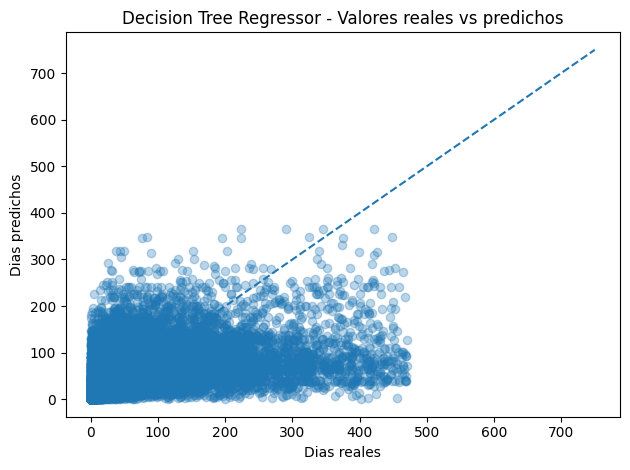

In [157]:
plt.scatter(
    yreg_val,
    ypred_dt_reg,
    alpha=0.3
)

plt.plot(
    [0, 750],
    [0, 750],
    linestyle='--'
)

plt.xlabel("Dias reales")
plt.ylabel("Dias predichos")
plt.title("Decision Tree Regressor - Valores reales vs predichos")

plt.tight_layout()
plt.show()

    Nuestro modelo esta encontrando patrones que funcionan para muchos registros, pero no consigue identificar correctamente algunos casos de larga duracion

### Random Forest Regresor

In [159]:
param_grid_rf_reg = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 0.7, 1.0]
}

kf_rf_reg = KFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

grid_rf_reg = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=67,
        n_jobs=1
    ),
    param_distributions=param_grid_rf_reg,
    n_iter=8,
    cv=kf_rf_reg,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    random_state=67,
    verbose=1
)

grid_rf_reg.fit(Xreg_train, yreg_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Mejores hiperparametros:
{'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None}

Mejor MAE en validacion cruzada:
28.23880494019859


In [160]:
print("Mejores hiperparametros:")
print(grid_rf_reg.best_params_)

print("\nMejor MAE en validacion cruzada:")
print(-grid_rf_reg.best_score_)

Mejores hiperparametros:
{'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': None}

Mejor MAE en validacion cruzada:
28.23880494019859


####    Resultado

In [209]:
mejor_rf_reg = grid_rf_reg.best_estimator_
ypred_rf_reg_test = mejor_rf_reg.predict(Xreg_test)
ypred_rf_reg = mejor_rf_reg.predict(Xreg_val)

print(" ")
print("test")
print("MAE:", mean_absolute_error(yreg_test, ypred_rf_reg_test))
print("MSE:", mean_squared_error(yreg_test, ypred_rf_reg_test))
print("RMSE:", np.sqrt(mean_squared_error(yreg_test, ypred_rf_reg_test)))
print("R2:", r2_score(yreg_test, ypred_rf_reg_test))
print(" ")
print("validation")
print("MAE:", mean_absolute_error(yreg_val, ypred_rf_reg))
print("MSE:", mean_squared_error(yreg_val, ypred_rf_reg))
print("RMSE:", np.sqrt(mean_squared_error(yreg_val, ypred_rf_reg)))
print("R2:", r2_score(yreg_val, ypred_rf_reg))

 
test
MAE: 27.722042152501242
MSE: 2563.8872256214345
RMSE: 50.63484201240717
R2: 0.3450544983072902
 
validation
MAE: 27.848841730172623
MSE: 2570.6501839160983
RMSE: 50.70157969842851
R2: 0.35059703950943355


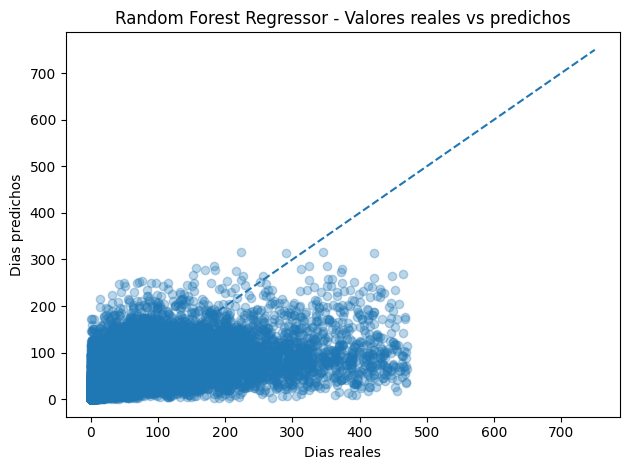

In [162]:
plt.scatter(
    yreg_val,
    ypred_rf_reg,
    alpha=0.3
)

plt.plot(
    [0, 750],
    [0, 750],
    linestyle='--'
)

plt.xlabel("Dias reales")
plt.ylabel("Dias predichos")
plt.title("Random Forest Regressor - Valores reales vs predichos")

plt.tight_layout()
plt.show()

### Linear Support Vector Regresor

In [165]:
pipeline_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVR(
        random_state=67,
        max_iter=3000
    ))
])

param_grid_svr = {
    'model__C': [0.1, 1, 10],
    'model__epsilon': [0.01, 0.5, 1.0]
}

kf_svr = KFold(
    n_splits=3,
    shuffle=True,
    random_state=67
)

grid_svr = RandomizedSearchCV(
    estimator=pipeline_svr,
    param_distributions=param_grid_svr,
    n_iter=5,
    cv=kf_svr,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    random_state=67,
    verbose=1
)

grid_svr.fit(Xreg_train, yreg_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=67))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [0.1, 1, ...], 'model__epsilon': [0.01, 0.5, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",67
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_

In [166]:
print("Mejores hiperparametros:")
print(grid_svr.best_params_)

print("\nMejor MAE en validacion cruzada:")
print(-grid_svr.best_score_)

Mejores hiperparametros:
{'model__epsilon': 1.0, 'model__C': 10}

Mejor MAE en validacion cruzada:
29.930436629615283


####    Resultado

In [210]:
mejor_svr = grid_svr.best_estimator_

ypred_svr_test = mejor_svr.predict(Xreg_test)
ypred_svr = mejor_svr.predict(Xreg_val)

print(" ")
print("test")
print("MAE:", mean_absolute_error(yreg_test, ypred_svr_test))
print("MSE:", mean_squared_error(yreg_test, ypred_svr_test))
print("RMSE:", np.sqrt(mean_squared_error(yreg_test, ypred_svr_test)))
print("R2:", r2_score(yreg_test, ypred_svr_test))
print(" ")
print("validation")
print("MAE:", mean_absolute_error(yreg_val, ypred_svr))
print("MSE:", mean_squared_error(yreg_val, ypred_svr))
print("RMSE:", np.sqrt(mean_squared_error(yreg_val, ypred_svr)))
print("R2:", r2_score(yreg_val, ypred_svr))

 
test
MAE: 29.64970756924728
MSE: 3492.5736686478017
RMSE: 59.098000546954225
R2: 0.10782136173838464
 
validation
MAE: 29.847039119840765
MSE: 3521.447348950257
RMSE: 59.34178417397186
R2: 0.1104046953070017


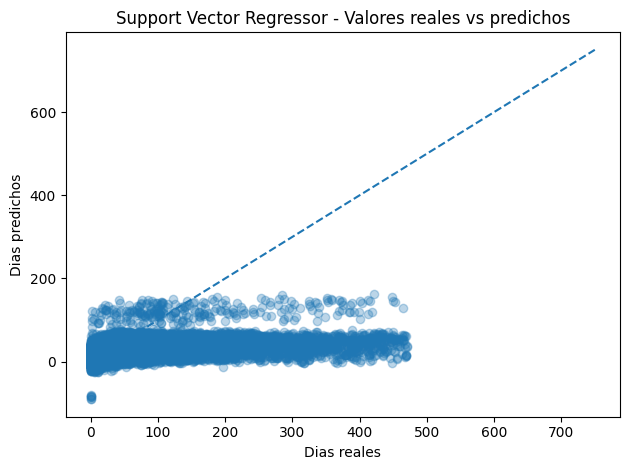

In [168]:
plt.scatter(
    yreg_val,
    ypred_svr,
    alpha=0.3
)
plt.plot(
    [0, 750],
    [0, 750],
    linestyle='--'
)
plt.xlabel("Dias reales")
plt.ylabel("Dias predichos")
plt.title("Support Vector Regressor - Valores reales vs predichos")

plt.tight_layout()
plt.show()

### Comparacion Regresor

In [169]:
resultados_regresion = {
    'Modelo': [
        'Decision Tree',
        'Random Forest',
        'Linear SVR'
    ],
    'MAE': [
        mean_absolute_error(yreg_val, ypred_dt_reg),
        mean_absolute_error(yreg_val, ypred_rf_reg),
        mean_absolute_error(yreg_val, ypred_svr)
    ],
    'MSE': [
        mean_squared_error(yreg_val, ypred_dt_reg),
        mean_squared_error(yreg_val, ypred_rf_reg),
        mean_squared_error(yreg_val, ypred_svr)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(yreg_val, ypred_dt_reg)),
        np.sqrt(mean_squared_error(yreg_val, ypred_rf_reg)),
        np.sqrt(mean_squared_error(yreg_val, ypred_svr))
    ],
    'R2': [
        r2_score(yreg_val, ypred_dt_reg),
        r2_score(yreg_val, ypred_rf_reg),
        r2_score(yreg_val, ypred_svr)
    ]
}

df_comparacion_reg = pd.DataFrame(resultados_regresion)

df_comparacion_reg = df_comparacion_reg.sort_values(
    by='MAE',
    ascending=True
).reset_index(drop=True)

df_comparacion_reg.round(4)

,Modelo,MAE,MSE,RMSE,R2
0,Random Forest,27.8488,2570.6502,50.7016,0.3506
1,Decision Tree,29.0782,2804.5575,52.9581,0.2915
2,Linear SVR,29.8470,3521.4473,59.3418,0.1104


In [ ]:
base = DummyRegressor(strategy='median')
base.fit(Xreg_train, yreg_train)
ypred_baseline = base.predict(Xreg_val)

def comparar_con_zona(modelos, X, y, tolerancias=(7, 14, 30, 60), tol_principal=30):
    assert tol_principal in tolerancias
    y = y.to_numpy()
    filas = []
    for nombre, m in modelos.items():
        error = np.abs(y - m.predict(X))
        fila = {'Modelo': nombre, 'MAE': error.mean()}
        for t in tolerancias:
            fila[f'% aceptable ±{t}d'] = (error <= t).mean() * 100
        fila['Score medio'] = np.mean([fila[f'% aceptable ±{t}d'] for t in tolerancias])
        filas.append(fila)

    return (pd.DataFrame(filas)
            .sort_values(f'% aceptable ±{tol_principal}d', ascending=False)
            .reset_index(drop=True))

intervalos = [0, 30, 90, 180, 365, np.inf]

etiquetas = [
    '0-30 dias',
    '31-90 dias',
    '91-180 dias',
    '181-365 dias',
    'Mas de 365 dias'
]

def analizar_errores_intervalos(y_real, y_predicho, nombre_modelo):

    df_errores = pd.DataFrame({
        'Real': np.array(y_real),
        'Predicho': np.array(y_predicho)
    })

    df_errores['Error'] = np.abs(
        df_errores['Real'] - df_errores['Predicho']
    )

    df_errores['Intervalo'] = pd.cut(
        df_errores['Real'],
        bins=intervalos,
        labels=etiquetas,
        include_lowest=True
    )

    resultados = df_errores.groupby(
        'Intervalo',
        observed=False
    ).agg(
        Registros=('Error', 'count'),
        MAE=('Error', 'mean'),
        RMSE=('Error', lambda x: np.sqrt(np.mean(x**2))),
        Aceptacion_7=('Error', lambda x: (x <= 7).mean() * 100),
        Aceptacion_14=('Error', lambda x: (x <= 14).mean() * 100),
        Aceptacion_30=('Error', lambda x: (x <= 30).mean() * 100)
    ).reset_index()

    resultados.insert(0, 'Modelo', nombre_modelo)

    return resultados

In [214]:
modelos_reg = {
    'Baseline (mediana)': base,
    'Decision Tree': mejor_dt_reg,
    'Random Forest': mejor_rf_reg,
    'SVR': mejor_svr
}

tabla_val = comparar_con_zona(modelos_reg, Xreg_val, yreg_val)
print(tabla_val.round(2))

nombre_mejor = tabla_val[tabla_val['Modelo'] != 'Baseline (mediana)'].iloc[0]['Modelo']

tabla_test = comparar_con_zona({nombre_mejor: modelos_reg[nombre_mejor]}, Xreg_test, yreg_test)
print(tabla_test.round(2))

               Modelo    MAE  % aceptable ±7d  % aceptable ±14d  \
0                 SVR  29.85            28.76             51.06   
1  Baseline (mediana)  36.02            18.34             38.23   
2       Random Forest  27.85            32.43             49.35   
3       Decision Tree  29.08            32.57             48.82   

   % aceptable ±30d  % aceptable ±60d  Score medio  
0             77.37             88.01        61.30  
1             74.38             84.77        53.93  
2             71.19             89.17        60.53  
3             70.24             88.16        59.95  
  Modelo    MAE  % aceptable ±7d  % aceptable ±14d  % aceptable ±30d  \
0    SVR  29.65            28.95             51.49             77.57   

   % aceptable ±60d  Score medio  
0             88.09        61.53  


In [179]:
resultados_intervalos = pd.concat([
    analizar_errores_intervalos(
        yreg_val,
        ypred_svr,
        'SVR'
    ),

    analizar_errores_intervalos(
        yreg_val,
        ypred_rf_reg,
        'Random Forest'
    ),

    analizar_errores_intervalos(
        yreg_val,
        ypred_dt_reg,
        'Decision Tree'
    )
], ignore_index=True)

resultados_intervalos.round(2)

,Modelo,Intervalo,Registros,MAE,RMSE,Aceptacion_7,Aceptacion_14,Aceptacion_30
0,SVR,0-30 dias,27429,11.69,15.00,37.86,66.06,95.67
1,SVR,31-90 dias,12472,20.49,26.09,22.96,43.22,75.06
2,SVR,91-180 dias,4229,82.88,87.82,0.21,0.64,1.51
3,SVR,181-365 dias,1649,202.47,209.94,0.00,0.00,0.06
4,SVR,Mas de 365 dias,319,361.98,364.49,0.00,0.00,0.00
5,Random Forest,0-30 dias,27429,15.55,24.39,45.02,63.97,83.24
6,Random Forest,31-90 dias,12472,24.38,31.96,18.48,36.63,69.11
7,Random Forest,91-180 dias,4229,49.10,58.35,6.79,14.54,31.26
8,Random Forest,181-365 dias,1649,151.05,164.32,0.61,1.15,2.67
9,Random Forest,Mas de 365 dias,319,301.84,309.30,0.00,0.00,0.00


## Seleccion Mejores Modelos ML: Classifier vs Regresor

    Inicialmente podemos decir que al manejar 2 target distintos la comparacion no es totalmente justa, de todos modos hay ciertos puntos de 
    comparacion que vale la pena mirar

### Mejor modelo de cada tarea

| | Classifier (`final_program`) | Regresor (`days_until_departure`) |
|---|---|---|
| **Modelo elegido** | Decision Tree | Random Forest |
| **Criterio de selección** | F1 Macro | MAE (con RMSE y R² de apoyo) |
| **Validación** | F1 Macro 0.659 · Accuracy 0.817 | MAE 27.85 días · R² 0.351 |
| **Test** | F1 Macro 0.66 · Accuracy 0.820 | MAE 27.72 días · R² 0.345 |

**Classifier: Decision Tree.** 

    El target está desbalanceado (ERO Criminal Alien Program es cerca del 74% de los registros que quedaron al filtrar las tres clases), así que el accuracy por sí solo engaña. Por eso elegimos con F1 Macro, la misma métrica que usamos en la búsqueda de hiperparámetros. Decision Tree (0.659) y Random Forest (0.653) quedan casi empatados: RF gana en accuracy y precision, pero DT recupera más casos de las clases pequeñas (recall macro 0.629 vs 0.613; recall de Non-Detained Docket Control 0.40 vs 0.34). SVM (0.608) y GaussianNB (0.358) quedan claramente por detrás. El costo es un árbol grande (profundidad 66 y 16,388 hojas), aunque el desempeño se mantiene entre validación y test.

**Regresor: Random Forest.** 

    Es el mejor en las tres métricas estándar en validación: MAE 27.85, RMSE 50.70 y R² 0.351, frente a Decision Tree (29.08 / 52.96 / 0.292) y Linear SVR (29.85 / 59.34 / 0.110), y se mantiene en test. En la zona de aceptación de ±30 días SVR queda primero (77.4%), pero ese umbral es muy permisivo: el baseline de la mediana ya logra 74.4%, por encima de Random Forest (71.2%) y Decision Tree (70.2%), porque la mayoría de los casos son cortos. SVR es mejor en 0-30 y 31-90 días, y desde los 91 días se desploma (MAE 82.9 vs 49.1 días de RF en 91-180 y 202.5 vs 151.1 en 181-365). Con tolerancias más exigentes Random Forest sí supera con claridad al baseline (±7 días: 32.4% vs 18.3%; ±14 días: 49.4% vs 38.2%) y su MAE es 27.85 contra 36.02 del baseline. Para todo el rango de duraciones, Random Forest es el más confiable.

### Puntos de comparación

    Como los targets son distintos, no tiene sentido comparar accuracy contra MAE directamente. Comparamos tres cosas que sí son equivalentes:

1. **Cuánto mejora cada modelo frente a un baseline trivial** (clase mayoritaria en el classifier, mediana en el regresor).

2. **Porcentaje de predicciones aceptables**, en una misma escala: en el classifier una predicción es aceptable si acierta la clase, y en el regresor si el error es de máximo 7, 14 o 30 días. Se prueban varias tolerancias porque el resultado del regresor depende de qué tan estricta sea.

3. **Dónde falla cada modelo**: por clase en el classifier y por rango de duración en el regresor.

In [ ]:
def metricas_clf(y_real, y_pred):
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision Macro': precision_score(y_real, y_pred, average='macro', zero_division=0),
        'Recall Macro': recall_score(y_real, y_pred, average='macro', zero_division=0),
        'F1 Macro': f1_score(y_real, y_pred, average='macro', zero_division=0)
    }

def metricas_reg(y_real, y_pred, tolerancia=30):
    error = np.abs(np.asarray(y_real) - np.asarray(y_pred))
    return {
        'MAE': error.mean(),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'R2': r2_score(y_real, y_pred),
        f'% aceptable ±{tolerancia}d': (error <= tolerancia).mean() * 100
    }

# Classifier: mejor modelo vs baseline
tabla_clf = pd.DataFrame([
    {'Modelo': 'Decision Tree', 'Conjunto': 'Validacion', **metricas_clf(yclas_val, mejor_dt.predict(Xclas_val))},
    {'Modelo': 'Decision Tree', 'Conjunto': 'Test', **metricas_clf(yclas_test, mejor_dt.predict(Xclas_test))}
])

# Regresor: mejor modelo vs baseline
tabla_reg = pd.DataFrame([
    {'Modelo': 'Baseline (mediana)', 'Conjunto': 'Validacion', **metricas_reg(yreg_val, base.predict(Xreg_val))},
    {'Modelo': 'Random Forest', 'Conjunto': 'Validacion', **metricas_reg(yreg_val, mejor_rf_reg.predict(Xreg_val))},
    {'Modelo': 'Random Forest', 'Conjunto': 'Test', **metricas_reg(yreg_test, mejor_rf_reg.predict(Xreg_test))}
])

print("Classifier (final_program)")
print(tabla_clf.round(4).to_string(index=False))
print("\nRegresor (days_until_departure)")
print(tabla_reg.round(4).to_string(index=False))

Classifier (final_program)
                      Modelo   Conjunto  Accuracy  Precision Macro  Recall Macro  F1 Macro
Baseline (clase mayoritaria) Validacion    0.7382           0.2461        0.3333    0.2831
               Decision Tree Validacion    0.8172           0.7078        0.6288    0.6592
               Decision Tree       Test    0.8197           0.7137        0.6326    0.6642

Regresor (days_until_departure)
            Modelo   Conjunto     MAE    RMSE      R2  % aceptable ±30d
Baseline (mediana) Validacion 36.0165 66.5960 -0.1204           74.3763
     Random Forest Validacion 27.8488 50.7016  0.3506           71.1918
     Random Forest       Test 27.7220 50.6348  0.3451           71.5142


In [220]:
# Escala comun: % de predicciones aceptables (validacion)
pred_clf_val = mejor_dt.predict(Xclas_val)
pred_reg_val = mejor_rf_reg.predict(Xreg_val)

error_modelo = np.abs(np.asarray(yreg_val) - pred_reg_val)
error_base = np.abs(np.asarray(yreg_val) - base.predict(Xreg_val))

comparacion = pd.DataFrame([
    {
        'Tarea': 'Classifier',
        'Modelo': 'Decision Tree',
        'Criterio de acierto': 'Clase correcta',
        '% modelo': accuracy_score(yclas_val, pred_clf_val) * 100
    },
    {
        'Tarea': 'Regresor',
        'Modelo': 'Random Forest',
        'Criterio de acierto': 'Error <= 30 dias',
        '% modelo': (error_modelo <= 30).mean() * 100,
        '% baseline': (error_base <= 30).mean() * 100
    }
])
comparacion['Mejora (puntos)'] = comparacion['% modelo'] - comparacion['% baseline']

print(comparacion.round(2).to_string(index=False))

     Tarea        Modelo Criterio de acierto  % modelo  % baseline  Mejora (puntos)
Classifier Decision Tree      Clase correcta     81.72         NaN              NaN
  Regresor Random Forest    Error <= 30 dias     71.19       74.38            -3.18


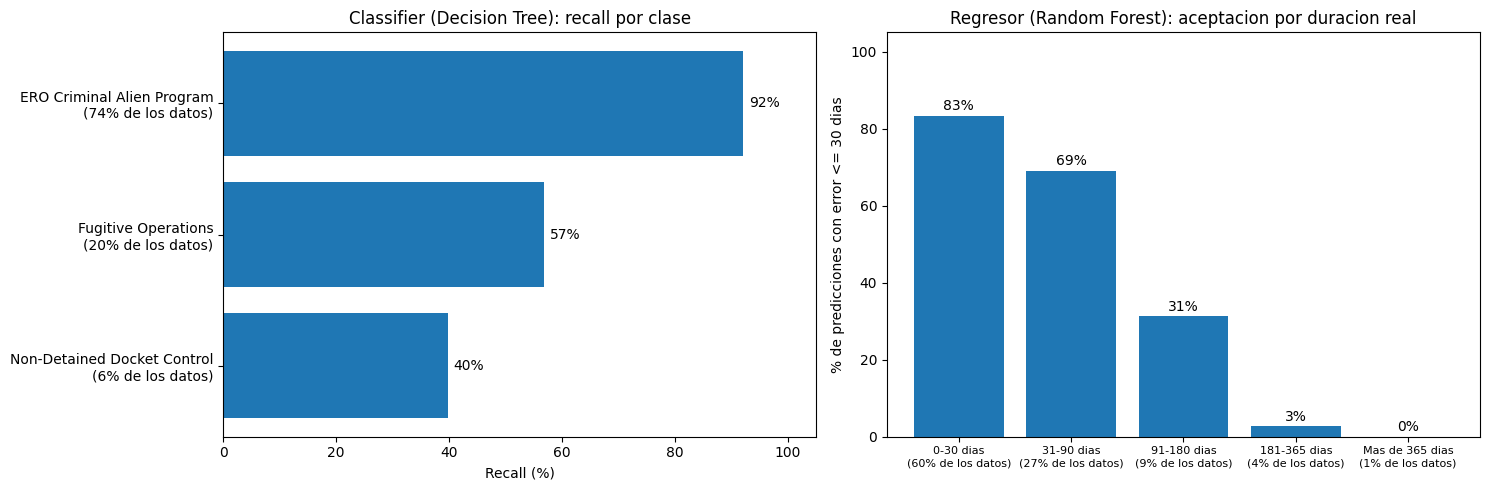

In [221]:
# Classifier: recall por clase y peso de cada clase en los datos
clases = mejor_dt.classes_
recall_clase = pd.Series(
    recall_score(yclas_val, pred_clf_val, average=None, labels=clases),
    index=clases
) * 100
peso_clase = pd.Series(np.asarray(yclas_val)).value_counts(normalize=True).reindex(clases) * 100

# Regresor: % aceptable (±30 dias) por rango de duracion real
tabla_intervalos = analizar_errores_intervalos(yreg_val, pred_reg_val, 'Random Forest')
peso_intervalo = tabla_intervalos['Registros'] / tabla_intervalos['Registros'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Classifier
etiquetas_clf = [f"{c}\n({p:.0f}% de los datos)" for c, p in zip(clases, peso_clase)]
axes[0].barh(etiquetas_clf, recall_clase.values)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 105)
axes[0].set_xlabel('Recall (%)')
axes[0].set_title('Classifier (Decision Tree): recall por clase')
for i, v in enumerate(recall_clase.values):
    axes[0].text(v + 1, i, f"{v:.0f}%", va='center')

# Regresor
etiquetas_reg = [f"{i}\n({p:.0f}% de los datos)" for i, p in zip(tabla_intervalos['Intervalo'], peso_intervalo)]
axes[1].bar(etiquetas_reg, tabla_intervalos['Aceptacion_30'].values)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel('% de predicciones con error <= 30 dias')
axes[1].set_title('Regresor (Random Forest): aceptacion por duracion real')
axes[1].tick_params(axis='x', labelsize=8)
for i, v in enumerate(tabla_intervalos['Aceptacion_30'].values):
    axes[1].text(i, v + 1.5, f"{v:.0f}%", ha='center')

plt.tight_layout()
plt.show()

# Conclusion

Los resultados nos dejan dos modelos finales, con niveles de utilidad distintos:

**1. Mejores modelos.** 

    Para predecir el programa (`final_program`) elegimos el **Decision Tree**, con F1 Macro de 0.659 y accuracy de 0.817 en validación, y resultados consistentes en test. Para estimar los días hasta la salida (`days_until_departure`) elegimos el **Random Forest**, con MAE de 27.8 días, RMSE de 50.7 y R² de 0.35.

**2. El classifier cumple mejor el objetivo que el regresor.** 

    Distinguir entre ERO Criminal Alien Program, Fugitive Operations y Non-Detained Docket Control es viable: el modelo supera claramente al baseline en F1 Macro, y es confiable sobre todo para la clase mayoritaria. En cambio, el regresor solo explica alrededor de un tercio de la variabilidad de la duración (R² 0.35). Sirve como estimación aproximada para estancias cortas (83% de aciertos dentro de ±30 días en casos de 0-30 días), pero no para casos largos: a partir de 91 días la mayoría de las predicciones queda fuera de la zona de aceptación, y por encima de 365 días ninguna entra.

**3. Limitaciones.** 

    Ambos modelos comparten el mismo patrón: aprenden bien los casos frecuentes y mal los poco frecuentes, ya sea una clase minoritaria (Non-Detained Docket Control, con recall de 0.40) o una duración larga. Probablemente las variables disponibles al momento del arresto no capturan lo que alarga un caso (por ejemplo, trámites o procesos posteriores), por lo que parte del error no se puede resolver solo cambiando de modelo. Además, el classifier se entrenó solo con las 3 clases más frecuentes, así que no predice los demás programas.